# AIMIP catalog check

Check of the `aimip` catalog with the AQUA `Reader`, one section per model.

- **Part 1**: commands that work (retrieve, field mean, regrid to `r100`, 1979 `2t` bias against ERA5).
- **Part 2**: commands that fail or give wrong results, with the problem in a comment. Cells are expected to raise.

Run with the `aqua-dev` kernel (the regridder needs `cdo` in the `PATH`).

In [9]:
import warnings

import matplotlib.pyplot as plt
import pandas as pd
from aqua import Reader
from aqua.core.graphics import plot_single_map

warnings.filterwarnings("ignore", message="Shell command not executed")  # intake noise

regrid = "r100"
period = slice("1979-01", "1979-12")

## Dask SLURM cluster (Levante)

One SLURM job on the `interactive` partition (account `bb1153`) with 2 dask workers; the kernel and the
scheduler stay where the notebook runs. The `compute` partition works too, but with a low fairshare the job
may stay pending for a long time: check with `squeue -u $USER`.
Needs `dask-jobqueue` in the `aqua-dev` environment.

In [10]:
from dask.distributed import Client
from dask_jobqueue import SLURMCluster

cluster = SLURMCluster(
    queue="interactive",
    account="bb1153",
    cores=4,              # cores per SLURM job
    processes=2,          # dask workers per job (2 threads each)
    memory="64GB",        # memory per job
    walltime="02:00:00",
    interface="ib0",      # Levante InfiniBand
    local_directory="/scratch/b/b382076/dask",
    log_directory="/scratch/b/b382076/dask/logs",
)
cluster.scale(jobs=1)
client = Client(cluster)
client.wait_for_workers(2, timeout=600)  # fails here if the SLURM job does not start
client

/work/bb1153/b382076/mambaforge/envs/aqua-dev/lib/python3.14/site-packages/distributed/node.py:195: UserWarning: Port 8787 is already in use.
Perhaps you already have a cluster running?
Hosting the HTTP server on port 44881 instead
  warnings.warn(


<Client: 'tcp://10.128.10.130:40639' processes=0 threads=0, memory=0 B>

# Part 1: working pipeline

## References: ERA5 and GPCP-SG

In [11]:
reader_era5 = Reader(catalog="aimip", model="ERA5", exp="era5", source="monthly-atm2d", regrid=regrid)
tas_era5 = reader_era5.retrieve(var="2t")["2t"].sel(time=period)
tas_era5_r = reader_era5.regrid(tas_era5).mean("time").compute()

reader_gpcp = Reader(catalog="aimip", model="GPCP-SG", exp="v2.3", source="monthly", regrid=regrid)
pr_gpcp = reader_gpcp.retrieve(var="tprate")["tprate"].sel(time=period)
pr_gpcp_r = reader_gpcp.regrid(pr_gpcp).mean("time").compute()

tas_models, pr_models = {}, {}  # 1979 means on r100, filled by each model section


def check_model(model, tas_r, pr_r=None):
    """Store the regridded 1979 means, print the 2t bias against ERA5 and plot it."""
    tas_models[model] = tas_r.compute()
    if pr_r is not None:
        pr_models[model] = pr_r.compute()
    bias = tas_models[model] - tas_era5_r
    print(f"{model}: 2t bias {float(reader_era5.fldmean(bias)):+.2f} K, "
          f"abs bias {float(reader_era5.fldmean(abs(bias))):.2f} K")
    plot_single_map(bias, sym=True, vmin=-5, vmax=5, cmap="RdBu_r", title=f"{model} - ERA5, 2t 1979")

2026-11-20 14:33:43 :: Regridder :: WARNING  -> Source grid path not found. Please provide a dataset.
2026-11-20 14:34:03 | smmregrid.Regrid |  WARNING -> Found scalar coordinates ['height']. If have selected a along a masked dimensions,regridding might fail. Please consider subsetting with [] or with slice
2026-11-20 14:34:10 :: Regridder :: WARNING  -> Source grid path not found. Please provide a dataset.


## ACE2-1-ERA5 (1 degree Gaussian)

2026-11-20 14:34:26 :: Regridder :: WARNING  -> Source grid path not found. Please provide a dataset.


('time', 'lat', 'lon') ['1979-01-01T00:00:00.000000' '1979-12-01T00:00:00.000000']
fldmean on r100: 287.4059918207326


2026-11-20 14:34:33 :: plot_single_map :: WARNING  -> sym=True, vmin and vmax given will be ignored


ACE2-1-ERA5: 2t bias +0.31 K, abs bias 0.42 K


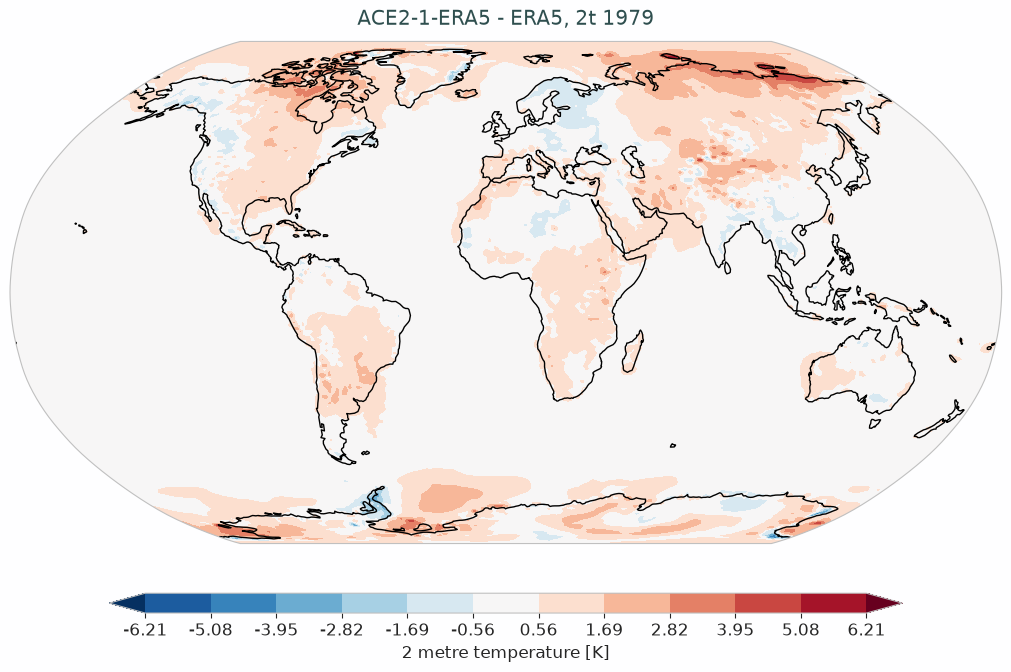

In [12]:
reader = Reader(catalog="aimip", model="ACE2-1-ERA5", exp="aimip", source="monthly-atm2d", regrid=regrid)
data = reader.retrieve(var=["2t", "tprate"]).sel(time=period)
print(data["2t"].dims, data.time.values[[0, -1]])  # monthly time stamps at the start of the month

tas_r, pr_r = reader.regrid(data["2t"]).mean("time"), reader.regrid(data["tprate"]).mean("time")
print("fldmean on r100:", float(reader_era5.fldmean(tas_r)))
check_model("ACE2-1-ERA5", tas_r, pr_r)

## ArchesWeather-V2 (1 degree, poles included, no precipitation)

2026-11-20 14:34:39 :: Regridder :: WARNING  -> Source grid path not found. Please provide a dataset.
2026-11-20 14:34:41 | smmregrid.Regrid |  WARNING -> Found scalar coordinates ['height']. If have selected a along a masked dimensions,regridding might fail. Please consider subsetting with [] or with slice
2026-11-20 14:34:41 :: plot_single_map :: WARNING  -> sym=True, vmin and vmax given will be ignored


fldmean native: 287.1644101920012
ArchesWeather-V2: 2t bias +0.07 K, abs bias 0.36 K


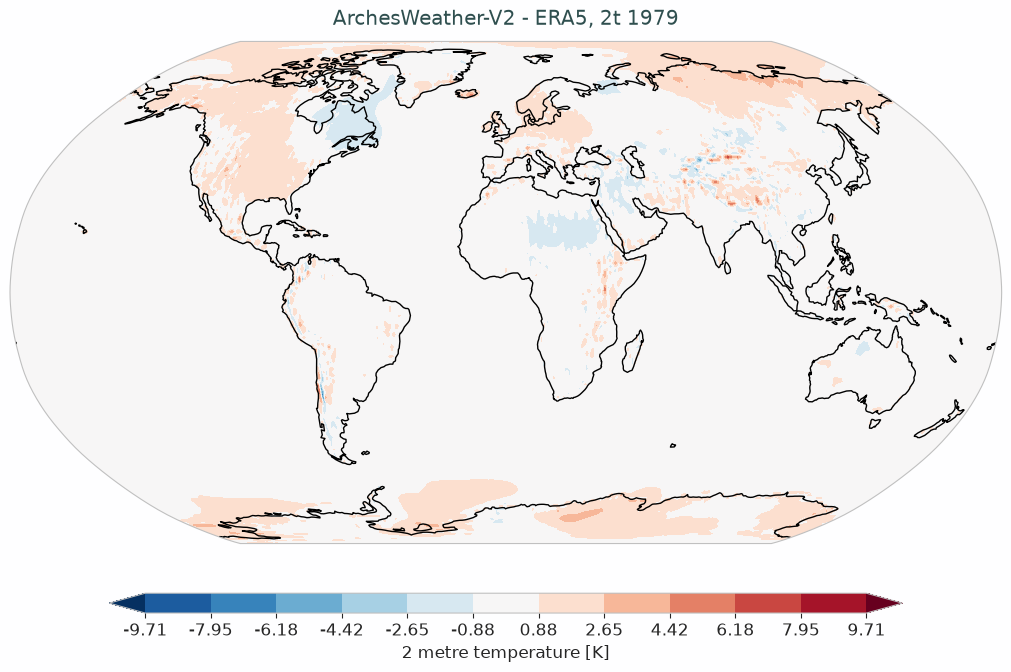

In [13]:
reader = Reader(catalog="aimip", model="ArchesWeather-V2", exp="aimip", source="monthly-atm2d", regrid=regrid)
data = reader.retrieve(var="2t").sel(time=period)
print("fldmean native:", reader.fldmean(data["2t"]).mean().values)
check_model("ArchesWeather-V2", reader.regrid(data["2t"]).mean("time"))

## ArchesWeatherGen-V2 (1 degree, poles included, no precipitation)

2026-11-20 14:34:46 :: Regridder :: WARNING  -> Source grid path not found. Please provide a dataset.
2026-11-20 14:34:47 | smmregrid.Regrid |  WARNING -> Found scalar coordinates ['height']. If have selected a along a masked dimensions,regridding might fail. Please consider subsetting with [] or with slice
2026-11-20 14:34:47 :: plot_single_map :: WARNING  -> sym=True, vmin and vmax given will be ignored


fldmean native: 287.1671860630278
ArchesWeatherGen-V2: 2t bias +0.07 K, abs bias 0.38 K


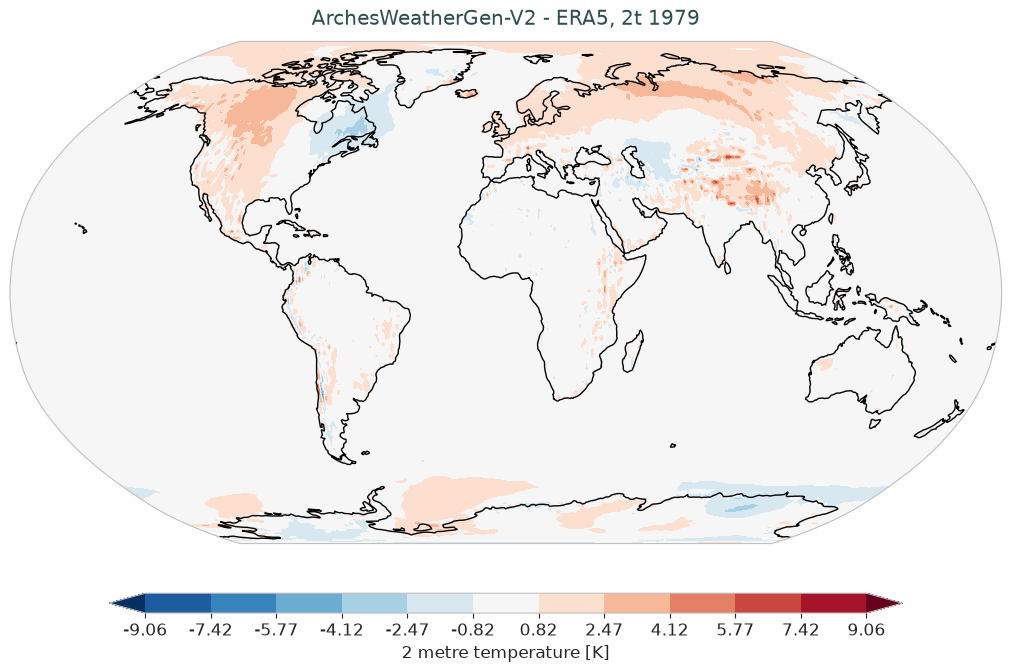

In [14]:
reader = Reader(catalog="aimip", model="ArchesWeatherGen-V2", exp="aimip", source="monthly-atm2d", regrid=regrid)
data = reader.retrieve(var="2t").sel(time=period)
print("fldmean native:", reader.fldmean(data["2t"]).mean().values)
check_model("ArchesWeatherGen-V2", reader.regrid(data["2t"]).mean("time"))

## NeuralGCM (TL63 Gaussian, data stored as `(time, lon, lat)`)

2026-11-20 14:34:52 :: Regridder :: WARNING  -> Source grid path not found. Please provide a dataset.
/work/bb1153/b382076/mambaforge/envs/aqua-dev/lib/python3.14/site-packages/intake/readers/readers.py:1334: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 12. This could degrade performance. Instead, consider rechunking after loading.
  return open_mfdataset(ofs, **kw)
/work/bb1153/b382076/mambaforge/envs/aqua-dev/lib/python3.14/site-packages/intake/readers/readers.py:1334: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 12. This could degrade performance. Instead, consider rechunking after loading.
  return open_mfdataset(ofs, **kw)
/work/bb1153/b382076/mambaforge/envs/aqua-dev/lib/python3.14/site-packages/intake/readers/readers.py:1334: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 12. This could degrade performance. Inste

('time', 'lon', 'lat') r3i1p1f1
fldmean native: 287.4224145069206


2026-11-20 14:34:54 :: plot_single_map :: WARNING  -> sym=True, vmin and vmax given will be ignored


NeuralGCM: 2t bias +0.33 K, abs bias 0.66 K


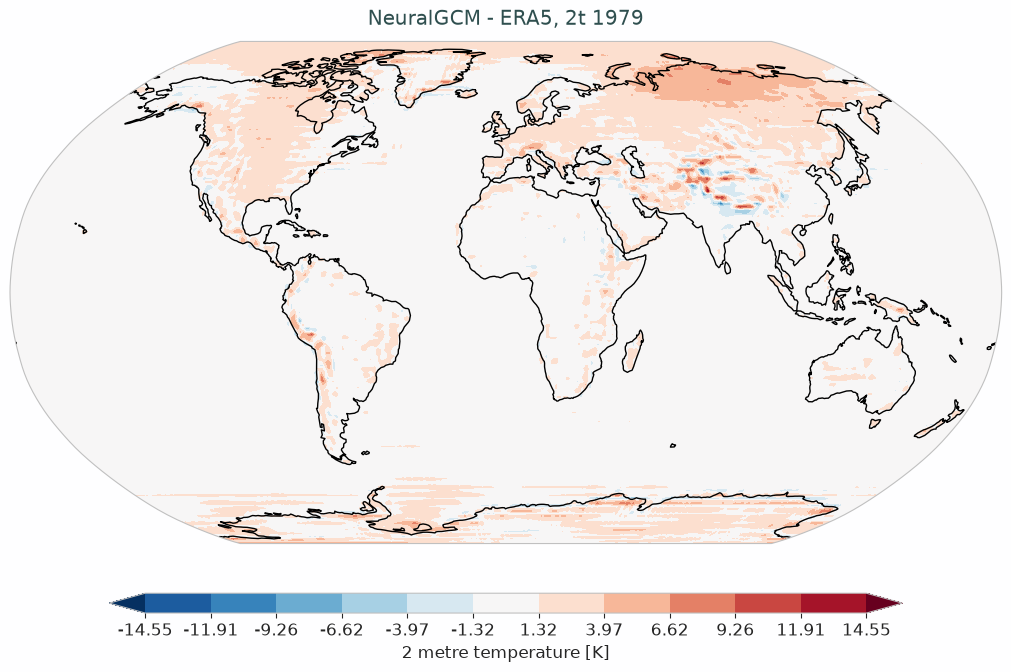

In [15]:
reader = Reader(catalog="aimip", model="NeuralGCM", exp="aimip", source="monthly-atm2d",
                realization="r3i1p1f1", regrid=regrid)
data = reader.retrieve(var=["2t", "tprate"]).sel(time=period)
print(data["2t"].dims, data.attrs["variant_label"])
print("fldmean native:", reader.fldmean(data["2t"]).mean().values)

# transpose to (time, lat, lon) before regridding, see Part 2
data = data.transpose("time", "lat", "lon")
check_model("NeuralGCM", reader.regrid(data["2t"]).mean("time"), reader.regrid(data["tprate"]).mean("time"))

## NeuralGCM-HRD (1 degree, data stored as `(time, lon, lat)`)

2026-11-20 14:35:06 :: Regridder :: WARNING  -> Source grid path not found. Please provide a dataset.
/work/bb1153/b382076/mambaforge/envs/aqua-dev/lib/python3.14/site-packages/intake/readers/readers.py:1334: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 12. This could degrade performance. Instead, consider rechunking after loading.
  return open_mfdataset(ofs, **kw)
/work/bb1153/b382076/mambaforge/envs/aqua-dev/lib/python3.14/site-packages/intake/readers/readers.py:1334: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 12. This could degrade performance. Instead, consider rechunking after loading.
  return open_mfdataset(ofs, **kw)
/work/bb1153/b382076/mambaforge/envs/aqua-dev/lib/python3.14/site-packages/intake/readers/readers.py:1334: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 12. This could degrade performance. Inste

('time', 'lon', 'lat')
fldmean native: 287.15219276383783


2026-11-20 14:35:08 :: plot_single_map :: WARNING  -> sym=True, vmin and vmax given will be ignored


NeuralGCM-HRD: 2t bias +0.06 K, abs bias 0.39 K


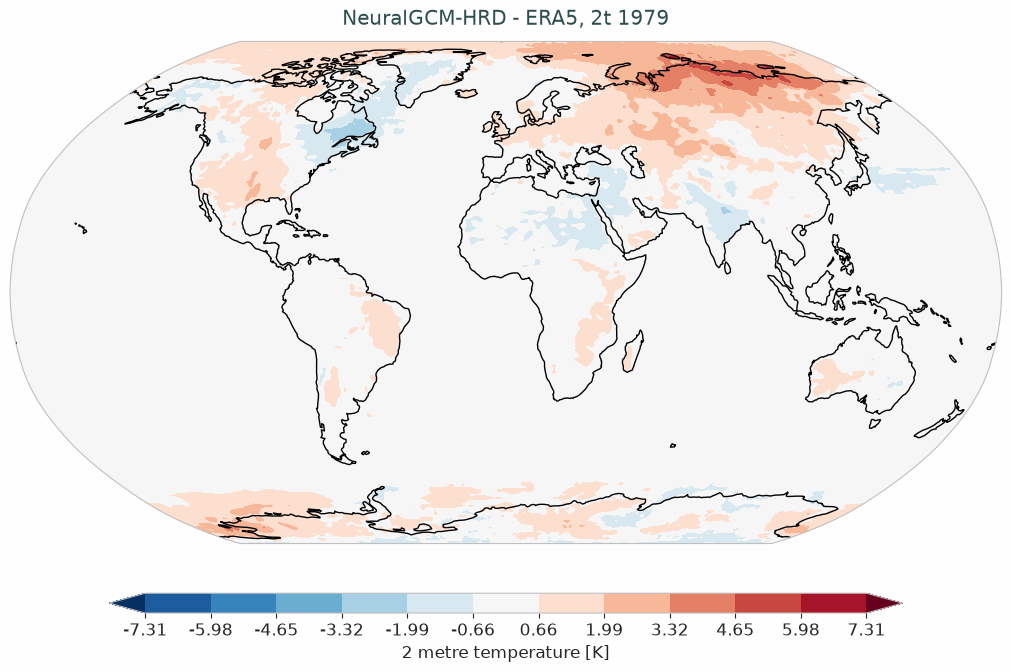

In [16]:
reader = Reader(catalog="aimip", model="NeuralGCM-HRD", exp="aimip", source="monthly-atm2d", regrid=regrid)
data = reader.retrieve(var=["2t", "tprate"]).sel(time=period)
print(data["2t"].dims)
print("fldmean native:", reader.fldmean(data["2t"]).mean().values)

data = data.transpose("time", "lat", "lon")  # see Part 2
check_model("NeuralGCM-HRD", reader.regrid(data["2t"]).mean("time"), reader.regrid(data["tprate"]).mean("time"))

## cBottle-1-3 (HEALPix nside=64, ring)

2026-11-20 14:35:12 :: Regridder :: WARNING  -> Horizontal dimensions not found in the grid path. Please provide a dataset. 
2026-11-20 14:35:12 :: FldStat :: WARNING  -> Area ['cells'] and data ['i'] have different horizontal dimensions! Renaming them!


('time', 'i')
fldmean native: 287.3570587222185


2026-11-20 14:35:13 | smmregrid.Regrid |  WARNING -> Found scalar coordinates ['height']. If have selected a along a masked dimensions,regridding might fail. Please consider subsetting with [] or with slice
2026-11-20 14:35:13 | smmregrid.Regrid |  WARNING -> Found scalar coordinates ['height']. If have selected a along a masked dimensions,regridding might fail. Please consider subsetting with [] or with slice
2026-11-20 14:35:13 :: plot_single_map :: WARNING  -> sym=True, vmin and vmax given will be ignored


cBottle-1-3: 2t bias +0.27 K, abs bias 0.43 K


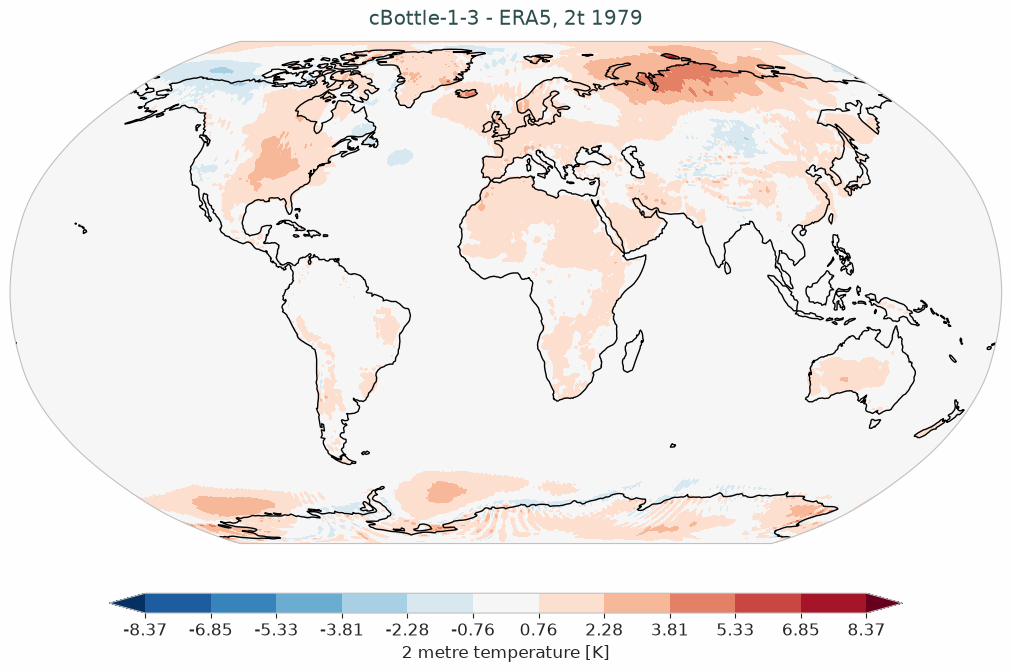

In [17]:
reader = Reader(catalog="aimip", model="cBottle-1-3", exp="aimip", source="monthly-atm2d",
                realization="r1i1p2f1", regrid=regrid)
data = reader.retrieve(var=["2t", "tprate"]).sel(time=period)
print(data["2t"].dims)

print("fldmean native:", reader.fldmean(data["2t"]).mean().values)
check_model("cBottle-1-3", reader.regrid(data["2t"]).mean("time"), reader.regrid(data["tprate"]).mean("time"))

## MD-1p5 (1 degree)

2026-11-20 14:35:19 :: Regridder :: WARNING  -> Source grid path not found. Please provide a dataset.
2026-11-20 14:35:21 | smmregrid.Regrid |  WARNING -> Found scalar coordinates ['height']. If have selected a along a masked dimensions,regridding might fail. Please consider subsetting with [] or with slice
2026-11-20 14:35:21 | smmregrid.Regrid |  WARNING -> Found scalar coordinates ['height']. If have selected a along a masked dimensions,regridding might fail. Please consider subsetting with [] or with slice


fldmean native: 287.1187280991823


2026-11-20 14:35:21 :: plot_single_map :: WARNING  -> sym=True, vmin and vmax given will be ignored


MD-1p5: 2t bias +0.03 K, abs bias 0.72 K


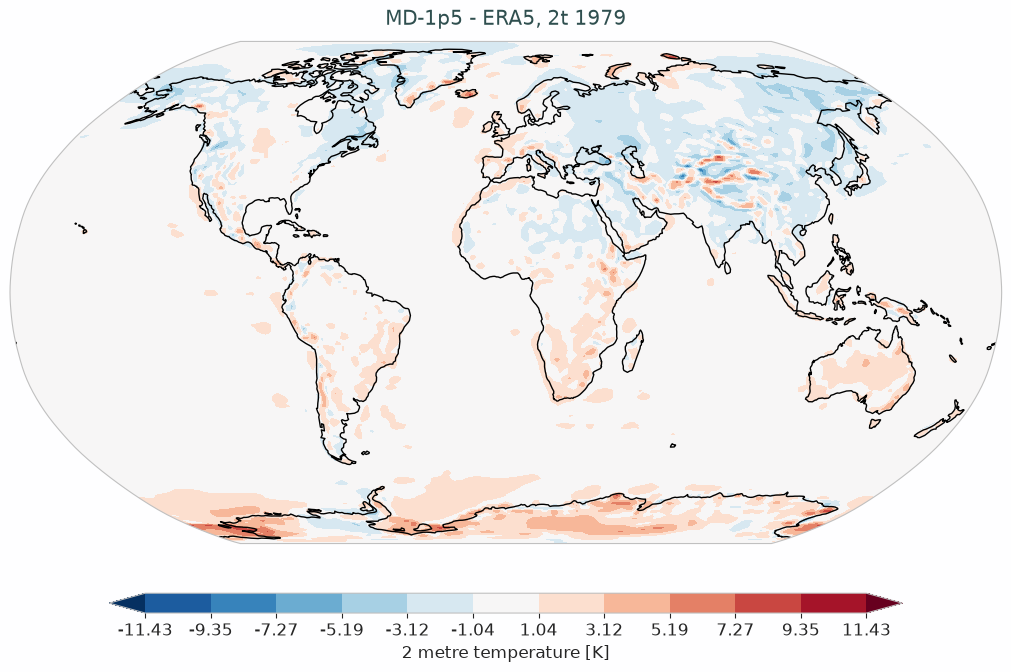

In [18]:
reader = Reader(catalog="aimip", model="MD-1p5", exp="aimip", source="monthly-atm2d", regrid=regrid)
data = reader.retrieve(var=["2t", "tprate"]).sel(time=period)
print("fldmean native:", reader.fldmean(data["2t"]).mean().values)
check_model("MD-1p5", reader.regrid(data["2t"]).mean("time"), reader.regrid(data["tprate"]).mean("time"))

## MPI-ESM1-2-LR (physical model, `amip`, 1979-2014)

2026-11-20 14:35:26 :: Regridder :: WARNING  -> Source grid path not found. Please provide a dataset.
2026-11-20 14:35:28 | smmregrid.Regrid |  WARNING -> Found scalar coordinates ['height']. If have selected a along a masked dimensions,regridding might fail. Please consider subsetting with [] or with slice
2026-11-20 14:35:28 | smmregrid.Regrid |  WARNING -> Found scalar coordinates ['height']. If have selected a along a masked dimensions,regridding might fail. Please consider subsetting with [] or with slice


fldmean native: 287.75626077817225


2026-11-20 14:35:32 :: plot_single_map :: WARNING  -> sym=True, vmin and vmax given will be ignored


MPI-ESM1-2-LR: 2t bias +0.66 K, abs bias 1.09 K


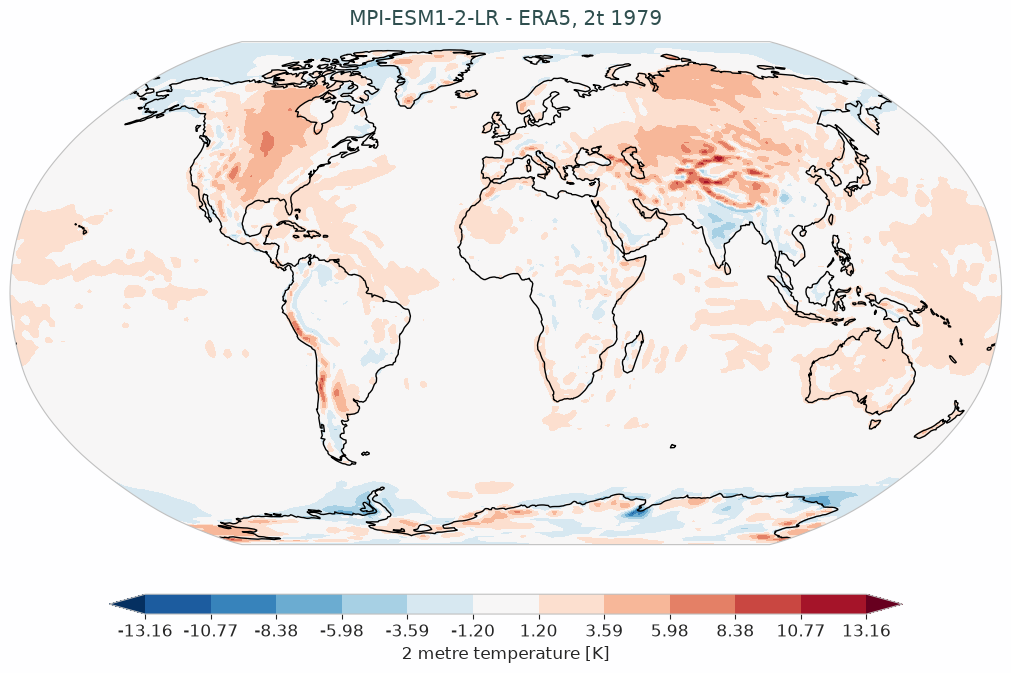

In [19]:
reader = Reader(catalog="aimip", model="MPI-ESM1-2-LR", exp="amip", source="monthly-atm2d", regrid=regrid)
data = reader.retrieve(var=["2t", "tprate"]).sel(time=period)
print("fldmean native:", reader.fldmean(data["2t"]).mean().values)
check_model("MPI-ESM1-2-LR", reader.regrid(data["2t"]).mean("time"), reader.regrid(data["tprate"]).mean("time"))

## DLESyM (HEALPix nside=64 by face, no AQUA grid): retrieve only

In [20]:
reader = Reader(catalog="aimip", model="DLESyM", exp="aimip", source="monthly-atm2d")
data = reader.retrieve(var=["2t", "tprate"]).sel(time=period)
print(data["2t"].dims, dict(data["2t"].sizes))
print("1979 mean 2t (unweighted):", float(data["2t"].mean()))

2026-11-20 14:35:37 :: Reader :: WARNING  -> Grid metadata is False, regrid and areas disabled
2026-11-20 14:35:37 :: FldStat :: WARNING  -> No horizontal dimensions provided, will try to guess from data when provided!
2026-11-20 14:35:37 :: FldStat :: WARNING  -> No area provided, no weighted area can be provided.
2026-11-20 14:35:37 :: CoordTransformer :: WARNING  -> Incompatible unit conversion for coordinate height: 1 -> m. Skipping conversion.


('time', 'face', 'height', 'width') {'time': 12, 'face': 12, 'height': 64, 'width': 64}
1979 mean 2t (unweighted): 287.05865478515625


## Summary

In [21]:
summary = pd.DataFrame({
    "bias [K]": {m: float(reader_era5.fldmean(t - tas_era5_r)) for m, t in tas_models.items()},
    "abs bias [K]": {m: float(reader_era5.fldmean(abs(t - tas_era5_r))) for m, t in tas_models.items()},
})
summary.round(2)

,bias [K],abs bias [K]
ACE2-1-ERA5,0.31,0.42
ArchesWeather-V2,0.07,0.36
ArchesWeatherGen-V2,0.07,0.38
NeuralGCM,0.33,0.66
NeuralGCM-HRD,0.06,0.39
cBottle-1-3,0.27,0.43
MD-1p5,0.03,0.72
MPI-ESM1-2-LR,0.66,1.09


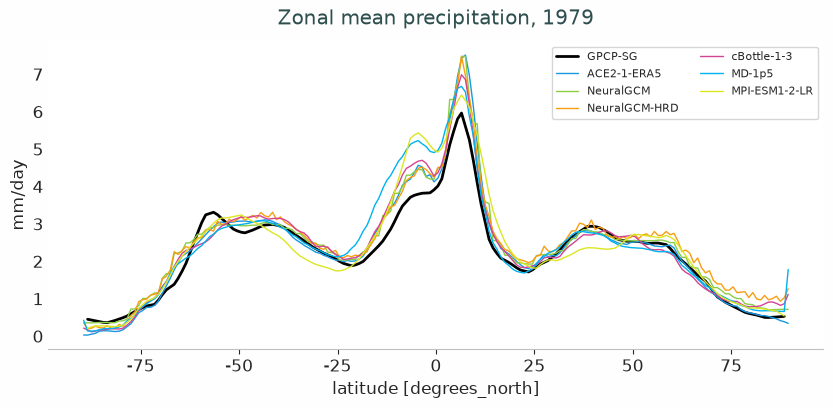

In [22]:
fig, ax = plt.subplots(figsize=(10, 4))
(pr_gpcp_r.mean("lon") * 86400).plot(ax=ax, color="k", lw=2, label="GPCP-SG")
for model, pr in pr_models.items():
    (pr.mean("lon") * 86400).plot(ax=ax, lw=1, label=model)
ax.set_ylabel("mm/day")
ax.set_title("Zonal mean precipitation, 1979")
ax.legend(ncol=2, fontsize=8)

In [23]:
# 3D sources: variables and pressure levels (hPa) of each model
models = {"ACE2-1-ERA5": "aimip", "ArchesWeather-V2": "aimip", "ArchesWeatherGen-V2": "aimip", "NeuralGCM": "aimip",
          "NeuralGCM-HRD": "aimip", "cBottle-1-3": "aimip", "MD-1p5": "aimip", "DLESyM": "aimip", "MPI-ESM1-2-LR": "amip"}
for model, exp in models.items():
    data3d = Reader(catalog="aimip", model=model, exp=exp, source="monthly-atm3d", loglevel="ERROR").retrieve()
    print(f"{model:>20}: {[v for v in data3d.data_vars if not v.endswith('bnds')]} "
          f"plev={(data3d.plev.values / 100).astype(int).tolist()}")

         ACE2-1-ERA5: ['q', 't', 'u', 'v', 'zg'] plev=[50, 100, 150, 200, 250, 300, 400, 500, 600, 700, 850, 925, 1000]
    ArchesWeather-V2: ['q', 't', 'u', 'v'] plev=[1000, 850, 700, 500, 250, 100, 50]
 ArchesWeatherGen-V2: ['q', 't', 'u', 'v'] plev=[1000, 850, 700, 500, 250, 100, 50]


/work/bb1153/b382076/mambaforge/envs/aqua-dev/lib/python3.14/site-packages/intake/readers/readers.py:1334: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 12. This could degrade performance. Instead, consider rechunking after loading.
  return open_mfdataset(ofs, **kw)
/work/bb1153/b382076/mambaforge/envs/aqua-dev/lib/python3.14/site-packages/intake/readers/readers.py:1334: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 12. This could degrade performance. Instead, consider rechunking after loading.
  return open_mfdataset(ofs, **kw)
/work/bb1153/b382076/mambaforge/envs/aqua-dev/lib/python3.14/site-packages/intake/readers/readers.py:1334: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 12. This could degrade performance. Instead, consider rechunking after loading.
  return open_mfdataset(ofs, **kw)
/work/bb1153/b382076/mambafo

           NeuralGCM: ['q', 't', 'u', 'v', 'zg'] plev=[1000, 850, 700, 500, 250, 100, 50]


/work/bb1153/b382076/mambaforge/envs/aqua-dev/lib/python3.14/site-packages/intake/readers/readers.py:1334: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 12. This could degrade performance. Instead, consider rechunking after loading.
  return open_mfdataset(ofs, **kw)
/work/bb1153/b382076/mambaforge/envs/aqua-dev/lib/python3.14/site-packages/intake/readers/readers.py:1334: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 12. This could degrade performance. Instead, consider rechunking after loading.
  return open_mfdataset(ofs, **kw)
/work/bb1153/b382076/mambaforge/envs/aqua-dev/lib/python3.14/site-packages/intake/readers/readers.py:1334: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 12. This could degrade performance. Instead, consider rechunking after loading.
  return open_mfdataset(ofs, **kw)
/work/bb1153/b382076/mambafo

       NeuralGCM-HRD: ['q', 't', 'u', 'v', 'zg'] plev=[1000, 850, 700, 500, 250, 100, 50]
         cBottle-1-3: ['q', 't', 'u', 'v', 'zg'] plev=[1000, 850, 700, 500, 300, 200, 50, 10]
              MD-1p5: ['q', 't', 'u', 'v', 'zg'] plev=[50, 100, 250, 500, 700, 850, 1000]
              DLESyM: ['t', 'zg'] plev=[250, 500, 850, 1000]
       MPI-ESM1-2-LR: ['q', 't', 'u', 'v', 'zg'] plev=[50, 100, 250, 500, 700, 850, 1000]


# Part 2: failing commands

Each cell reproduces one problem and is expected to raise. Run them one by one.

## ACE2-1-ERA5

In [ ]:
# Problem: field mean on the native grid fails.
# ValueError: Mismatch in values for coordinate 'lon' between data and areas.
# The single precision longitudes of the files differ from the ones of the areas by slightly more than the
# AQUA tolerance (already noted in the catalog README).
reader = Reader(catalog="aimip", model="ACE2-1-ERA5", exp="aimip", source="monthly-atm2d")
reader.fldmean(reader.retrieve(var="2t")["2t"].isel(time=0))

## ArchesWeather-V2 / ArchesWeatherGen-V2

In [ ]:
# Problem: spurious last time step.
# The monthly sources have 556 steps instead of 555: after 2024-12-16 there is an extra step at 2025-01-01
# (it comes from one of the variable files). Same for ArchesWeatherGen-V2.
reader = Reader(catalog="aimip", model="ArchesWeather-V2", exp="aimip", source="monthly-atm2d")
time = reader.retrieve(var="2t").time
print(time.values[-3:])
assert time.values[-1] < pd.Timestamp("2025-01-01"), "time axis goes beyond December 2024"

## NeuralGCM / NeuralGCM-HRD

In [ ]:
# Problem: silently wrong regridding.
# The data are stored as (time, lon, lat). The regridder does not raise, but the output field is scrambled:
# the 1979 2t bias against ERA5 becomes about -8 K (about 20 K in absolute value) instead of +0.06 K.
# Same for NeuralGCM-HRD. Workaround used in Part 1: transpose to (time, lat, lon) before regrid().
reader = Reader(catalog="aimip", model="NeuralGCM", exp="aimip", source="monthly-atm2d", regrid=regrid)
tas_r = reader.regrid(reader.retrieve(var="2t")["2t"].sel(time=period)).mean("time")
bias = float(reader_era5.fldmean(tas_r - tas_era5_r))
print(f"bias {bias:+.2f} K")
assert abs(bias) < 1, "regridded field is scrambled"

## DLESyM

In [ ]:
# Problem: no AQUA grid (source_grid_name: false), so no regridding.
# NoRegridError: regrid has not been initialized in the Reader. Expected, as documented in the catalog README.
reader = Reader(catalog="aimip", model="DLESyM", exp="aimip", source="monthly-atm2d", regrid=regrid)
reader.regrid(reader.retrieve(var="2t")["2t"].isel(time=0))

In [ ]:
# Problem: field mean fails without a grid.
# IndexError: list index out of range (an explicit error would be better).
reader = Reader(catalog="aimip", model="DLESyM", exp="aimip", source="monthly-atm2d")
reader.fldmean(reader.retrieve(var="2t")["2t"].isel(time=0))

# Close the cluster

In [ ]:
client.close()
cluster.close()